In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt



In [2]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier



In [3]:
try:
    df = pd.read_csv("/home/patel-krish/anaconda3/BrainyBeam/heart.csv")
except FileNotFoundError:
    df = pd.read_csv("/home/patel-krish/anaconda3/BrainyBeam/heart.csv")



In [4]:
df = df.drop_duplicates()
df = df.dropna(subset=["target"])

X = df.drop(columns=["target"])
y = df["target"].astype(int)

X = X.apply(pd.to_numeric, errors="coerce")

X = X.dropna(axis=1, how="all")

print("Dataset shape:", X.shape)
print("\nTarget distribution:")
print(y.value_counts())

print("\nAvailable demographic columns:")
print([col for col in ["sex", "age"] if col in X.columns])

Dataset shape: (302, 13)

Target distribution:
target
1    164
0    138
Name: count, dtype: int64

Available demographic columns:
['sex', 'age']


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 241
Testing records: 61


In [6]:
imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

model = RandomForestClassifier(
    n_estimators=150,
    max_depth=8,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train_imputed, y_train)

test_probabilities = model.predict_proba(
    X_test_imputed
)[:, 1]

test_predictions = (
    test_probabilities >= 0.50
).astype(int)

print("Model training completed.")
print("Predictions generated.")

Model training completed.
Predictions generated.


In [7]:
imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

model = RandomForestClassifier(
    n_estimators=150,
    max_depth=8,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train_imputed, y_train)

test_probabilities = model.predict_proba(
    X_test_imputed
)[:, 1]

test_predictions = (
    test_probabilities >= 0.50
).astype(int)

print("Model training completed.")
print("Predictions generated.")

Model training completed.
Predictions generated.


In [8]:
demographic_df = X_test.copy()

demographic_df["Actual"] = np.array(y_test)
demographic_df["Predicted"] = test_predictions

if "age" in demographic_df.columns:

    demographic_df["Age_Group"] = pd.cut(
        demographic_df["age"],
        bins=[0, 40, 50, 60, 70, 120],
        labels=[
            "Below 40",
            "40-49",
            "50-59",
            "60-69",
            "70 and above"
        ],
        right=False
    )

if "sex" in demographic_df.columns:
    print("SEX GROUP COUNTS")
    display(demographic_df["sex"].value_counts(dropna=False))

if "Age_Group" in demographic_df.columns:
    print("\nAGE GROUP COUNTS")
    display(demographic_df["Age_Group"].value_counts(dropna=False))

SEX GROUP COUNTS


sex
1    43
0    18
Name: count, dtype: int64


AGE GROUP COUNTS


Age_Group
50-59           23
60-69           21
40-49           11
Below 40         3
70 and above     3
Name: count, dtype: int64

In [9]:
def calculate_group_metrics(group_data):

    actual = np.array(group_data["Actual"])
    predicted = np.array(group_data["Predicted"])

    tp = np.sum((actual == 1) & (predicted == 1))
    fp = np.sum((actual == 0) & (predicted == 1))
    tn = np.sum((actual == 0) & (predicted == 0))
    fn = np.sum((actual == 1) & (predicted == 0))

    total = len(actual)

    selection_rate = (
        np.sum(predicted == 1) / total
        if total > 0 else np.nan
    )

    tpr = (
        tp / (tp + fn)
        if (tp + fn) > 0 else np.nan
    )

    fpr = (
        fp / (fp + tn)
        if (fp + tn) > 0 else np.nan
    )

    return {
        "Sample_Count": total,
        "Positive_Predictions": int(np.sum(predicted == 1)),
        "Selection_Rate": selection_rate,
        "TPR": tpr,
        "FPR": fpr,
        "TP": int(tp),
        "FP": int(fp),
        "TN": int(tn),
        "FN": int(fn)
    }


def manual_fairness_analysis(data, group_column):

    rows = []

    for group_value, group_data in data.groupby(
        group_column,
        observed=True,
        dropna=False
    ):

        metrics = calculate_group_metrics(group_data)

        metrics["Group"] = str(group_value)
        rows.append(metrics)

    result = pd.DataFrame(rows)

    
    highest_selection_rate = result["Selection_Rate"].max()

    if highest_selection_rate > 0:

        result["Disparate_Impact"] = (
            result["Selection_Rate"] /
            highest_selection_rate
        )

    else:
        result["Disparate_Impact"] = np.nan

    reference_index = result["Selection_Rate"].idxmax()

    reference_tpr = result.loc[reference_index, "TPR"]
    reference_fpr = result.loc[reference_index, "FPR"]

    result["Equal_Opportunity_Difference"] = (
        result["TPR"] - reference_tpr
    )

    result["TPR_Gap_From_Reference"] = (
        result["TPR"] - reference_tpr
    ).abs()

    result["FPR_Gap_From_Reference"] = (
        result["FPR"] - reference_fpr
    ).abs()

    return result

In [10]:
if "sex" in demographic_df.columns:

    sex_fairness = manual_fairness_analysis(
        demographic_df,
        "sex"
    )

    print("FAIRNESS ANALYSIS BY SEX")
    display(sex_fairness.round(4))

else:
    sex_fairness = pd.DataFrame()
    print("The sex column is not available.")

FAIRNESS ANALYSIS BY SEX


,Sample_Count,Positive_Predictions,Selection_Rate,TPR,FPR,TP,FP,TN,FN,Group,Disparate_Impact,Equal_Opportunity_Difference,TPR_Gap_From_Reference,FPR_Gap_From_Reference
0,18,12,0.6667,0.8462,0.2000,11,1,4,2,0,1.0000,0.0000,0.0000,0.0000
1,43,21,0.4884,0.7500,0.2609,15,6,17,5,1,0.7326,-0.0962,0.0962,0.0609


In [11]:
if "Age_Group" in demographic_df.columns:

    age_fairness = manual_fairness_analysis(
        demographic_df,
        "Age_Group"
    )

    print("FAIRNESS ANALYSIS BY AGE GROUP")
    display(age_fairness.round(4))

else:
    age_fairness = pd.DataFrame()
    print("The age column is not available.")

FAIRNESS ANALYSIS BY AGE GROUP


,Sample_Count,Positive_Predictions,Selection_Rate,TPR,FPR,TP,FP,TN,FN,Group,Disparate_Impact,Equal_Opportunity_Difference,TPR_Gap_From_Reference,FPR_Gap_From_Reference
0,3,3,1.0000,1.0000,1.0000,2,1,0,0,Below 40,1.0000,0.0000,0.0000,0.0000
1,11,11,1.0000,1.0000,1.0000,10,1,0,0,40-49,1.0000,0.0000,0.0000,0.0000
2,23,13,0.5652,0.7857,0.2222,11,2,7,3,50-59,0.5652,-0.2143,0.2143,0.7778
3,21,5,0.2381,0.3333,0.2000,2,3,12,4,60-69,0.2381,-0.6667,0.6667,0.8000
4,3,1,0.3333,1.0000,0.0000,1,0,2,0,70 and above,0.3333,0.0000,0.0000,1.0000


In [12]:
def calculate_overall_fairness_gaps(fairness_df, group_name):

    if len(fairness_df) < 2:
        return {
            "Demographic": group_name,
            "Number_of_Groups": len(fairness_df),
            "Disparate_Impact_Ratio_Min": np.nan,
            "Selection_Rate_Gap": np.nan,
            "Equal_Opportunity_Gap": np.nan,
            "FPR_Gap": np.nan,
            "Equalized_Odds_Gap": np.nan
        }

    selection_rates = fairness_df["Selection_Rate"].dropna()
    tpr_values = fairness_df["TPR"].dropna()
    fpr_values = fairness_df["FPR"].dropna()
    di_values = fairness_df["Disparate_Impact"].dropna()

    selection_gap = (
        selection_rates.max() - selection_rates.min()
        if len(selection_rates) else np.nan
    )

    tpr_gap = (
        tpr_values.max() - tpr_values.min()
        if len(tpr_values) else np.nan
    )

    fpr_gap = (
        fpr_values.max() - fpr_values.min()
        if len(fpr_values) else np.nan
    )

    equalized_odds_gap = (
        max(tpr_gap, fpr_gap)
        if not np.isnan(tpr_gap) and not np.isnan(fpr_gap)
        else np.nan
    )

    return {
        "Demographic": group_name,
        "Number_of_Groups": len(fairness_df),
        "Disparate_Impact_Ratio_Min": (
            di_values.min() if len(di_values) else np.nan
        ),
        "Selection_Rate_Gap": selection_gap,
        "Equal_Opportunity_Gap": tpr_gap,
        "FPR_Gap": fpr_gap,
        "Equalized_Odds_Gap": equalized_odds_gap
    }


overall_results = []

if len(sex_fairness) > 0:
    overall_results.append(
        calculate_overall_fairness_gaps(
            sex_fairness,
            "Sex"
        )
    )

if len(age_fairness) > 0:
    overall_results.append(
        calculate_overall_fairness_gaps(
            age_fairness,
            "Age Group"
        )
    )

overall_fairness_df = pd.DataFrame(overall_results)

print("OVERALL FAIRNESS GAP SUMMARY")
display(overall_fairness_df.round(4))

OVERALL FAIRNESS GAP SUMMARY


,Demographic,Number_of_Groups,Disparate_Impact_Ratio_Min,Selection_Rate_Gap,Equal_Opportunity_Gap,FPR_Gap,Equalized_Odds_Gap
0,Sex,2,0.7326,0.1783,0.0962,0.0609,0.0962
1,Age Group,5,0.2381,0.7619,0.6667,1.0000,1.0000


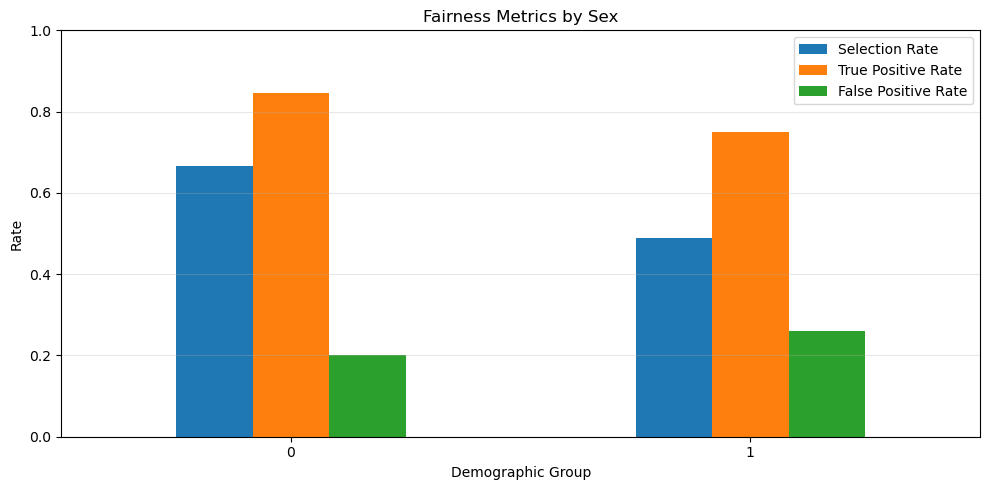

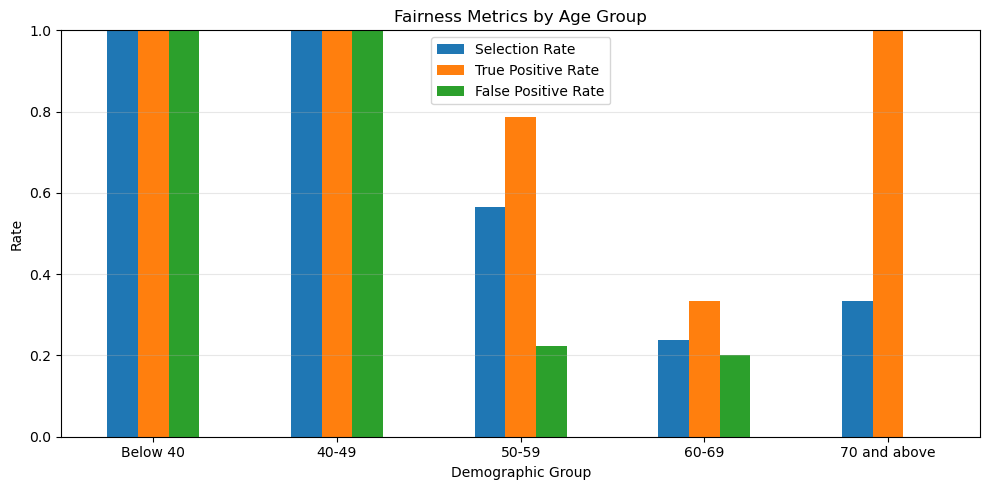

In [13]:

def plot_fairness_metrics(fairness_df, demographic_name):

    if fairness_df.empty:
        print("No fairness results available for", demographic_name)
        return

    plot_columns = [
        "Selection_Rate",
        "TPR",
        "FPR"
    ]

    fairness_df.plot(
        x="Group",
        y=plot_columns,
        kind="bar",
        figsize=(10, 5)
    )

    plt.title("Fairness Metrics by " + demographic_name)
    plt.xlabel("Demographic Group")
    plt.ylabel("Rate")
    plt.xticks(rotation=0)
    plt.ylim(0, 1)
    plt.legend(
        ["Selection Rate", "True Positive Rate", "False Positive Rate"]
    )
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()


if not sex_fairness.empty:
    plot_fairness_metrics(sex_fairness, "Sex")

if not age_fairness.empty:
    plot_fairness_metrics(age_fairness, "Age Group")

In [14]:
def identify_fairness_concerns(fairness_df, demographic_name):

    findings = []

    if fairness_df.empty:
        return [
            f"No sufficient data to assess {demographic_name} groups."
        ]

    for _, row in fairness_df.iterrows():

        group = row["Group"]

        if (
            pd.notna(row["Disparate_Impact"]) and
            row["Disparate_Impact"] < 0.80
        ):
            findings.append(
                f"{demographic_name} group {group} has a positive "
                "prediction rate below 80% of the highest-rate group. "
                "This is a screening signal for further review."
            )

        if (
            pd.notna(row["Equal_Opportunity_Difference"]) and
            abs(row["Equal_Opportunity_Difference"]) >= 0.10
        ):
            findings.append(
                f"{demographic_name} group {group} has a TPR difference "
                "of at least 10 percentage points from the reference group."
            )

        if (
            pd.notna(row["FPR_Gap_From_Reference"]) and
            row["FPR_Gap_From_Reference"] >= 0.10
        ):
            findings.append(
                f"{demographic_name} group {group} has an FPR difference "
                "of at least 10 percentage points from the reference group."
            )

    if not findings:
        findings.append(
            f"No group crossed the selected descriptive screening "
            f"thresholds for {demographic_name}. This does not prove "
            "that the model is free from bias."
        )

    return findings


fairness_findings = []

if not sex_fairness.empty:
    fairness_findings.extend(
        identify_fairness_concerns(sex_fairness, "Sex")
    )

if not age_fairness.empty:
    fairness_findings.extend(
        identify_fairness_concerns(age_fairness, "Age Group")
    )

print("FAIRNESS INVESTIGATION FINDINGS\n")

for number, finding in enumerate(fairness_findings, start=1):
    print(f"{number}. {finding}")

FAIRNESS INVESTIGATION FINDINGS

1. Sex group 1 has a positive prediction rate below 80% of the highest-rate group. This is a screening signal for further review.
2. Age Group group 50-59 has a positive prediction rate below 80% of the highest-rate group. This is a screening signal for further review.
3. Age Group group 50-59 has a TPR difference of at least 10 percentage points from the reference group.
4. Age Group group 50-59 has an FPR difference of at least 10 percentage points from the reference group.
5. Age Group group 60-69 has a positive prediction rate below 80% of the highest-rate group. This is a screening signal for further review.
6. Age Group group 60-69 has a TPR difference of at least 10 percentage points from the reference group.
7. Age Group group 60-69 has an FPR difference of at least 10 percentage points from the reference group.
8. Age Group group 70 and above has a positive prediction rate below 80% of the highest-rate group. This is a screening signal for furt

In [15]:
def calculate_fairness_summary(fairness_df, demographic_name):

    if len(fairness_df) < 2:
        return {
            "Demographic": demographic_name,
            "Disparate_Impact_Min": np.nan,
            "Selection_Rate_Gap": np.nan,
            "Equal_Opportunity_Gap": np.nan,
            "FPR_Gap": np.nan,
            "Equalized_Odds_Gap": np.nan
        }

    # Require valid rates for every group
    all_tpr_available = fairness_df["TPR"].notna().all()
    all_fpr_available = fairness_df["FPR"].notna().all()

    selection_gap = (
        fairness_df["Selection_Rate"].max() -
        fairness_df["Selection_Rate"].min()
    )

    di_min = fairness_df["Disparate_Impact"].min()

    if all_tpr_available:
        tpr_gap = (
            fairness_df["TPR"].max() -
            fairness_df["TPR"].min()
        )
    else:
        tpr_gap = np.nan

    if all_fpr_available:
        fpr_gap = (
            fairness_df["FPR"].max() -
            fairness_df["FPR"].min()
        )
    else:
        fpr_gap = np.nan

    if pd.notna(tpr_gap) and pd.notna(fpr_gap):
        eo_gap = max(tpr_gap, fpr_gap)
    else:
        eo_gap = np.nan

    return {
        "Demographic": demographic_name,
        "Disparate_Impact_Min": di_min,
        "Selection_Rate_Gap": selection_gap,
        "Equal_Opportunity_Gap": tpr_gap,
        "FPR_Gap": fpr_gap,
        "Equalized_Odds_Gap": eo_gap
    }


summary_rows = []

if not sex_fairness.empty:
    summary_rows.append(
        calculate_fairness_summary(sex_fairness, "Sex")
    )

if not age_fairness.empty:
    summary_rows.append(
        calculate_fairness_summary(age_fairness, "Age Group")
    )

final_fairness_summary = pd.DataFrame(summary_rows)

display(final_fairness_summary.round(4))

,Demographic,Disparate_Impact_Min,Selection_Rate_Gap,Equal_Opportunity_Gap,FPR_Gap,Equalized_Odds_Gap
0,Sex,0.7326,0.1783,0.0962,0.0609,0.0962
1,Age Group,0.2381,0.7619,0.6667,1.0000,1.0000


In [16]:
from datetime import datetime

report = []

report.append("# Model Fairness and Bias Analysis")
report.append("")
report.append("Generated: " + datetime.now().strftime("%Y-%m-%d %H:%M"))
report.append("")

report.append("## 1. Objective")
report.append(
    "This analysis investigates whether the heart disease prediction "
    "model produces different outcomes across demographic groups."
)
report.append("")

report.append("## 2. Fairness Metrics")
report.append("")
report.append(
    "- Disparate impact: Ratio of a group's positive prediction rate "
    "to the highest group's positive prediction rate."
)
report.append(
    "- Equal opportunity: Difference in true positive rates between groups."
)
report.append(
    "- Equalized odds: Comparison of both true positive rates and "
    "false positive rates across groups."
)
report.append("")

report.append("## 3. Sex Group Results")
report.append("")

if not sex_fairness.empty:
    report.append(sex_fairness.round(4).to_string(index=False))
else:
    report.append("Sex group analysis was unavailable.")

report.append("")

report.append("## 4. Age Group Results")
report.append("")

if not age_fairness.empty:
    report.append(age_fairness.round(4).to_string(index=False))
else:
    report.append("Age group analysis was unavailable.")

report.append("")

report.append("## 5. Overall Fairness Gaps")
report.append("")

report.append(
    final_fairness_summary.round(4).to_string(index=False)
    if not final_fairness_summary.empty
    else "No overall fairness results available."
)

report.append("")

report.append("## 6. Findings")
report.append("")

for finding in fairness_findings:
    report.append("- " + finding)

report.append("")

report.append("## 7. Recommendations")
report.append("")
report.append(
    "- Collect representative data from all demographic groups."
)
report.append(
    "- Investigate differences in false-positive and false-negative rates."
)
report.append(
    "- Evaluate fairness using repeated stratified validation."
)
report.append(
    "- Check whether differences are caused by sample size, data quality, "
    "model behaviour, or other relevant factors."
)
report.append(
    "- Review fairness findings with qualified healthcare professionals."
)
report.append(
    "- Monitor group-level metrics after model updates."
)

report.append("")
report.append("## 8. Limitations")
report.append("")
report.append(
    "- Small demographic groups can produce unstable fairness estimates."
)
report.append(
    "- Disparate impact and equalized odds measure different aspects of fairness."
)
report.append(
    "- A difference in positive prediction rates does not automatically "
    "indicate discrimination in a healthcare prediction task."
)
report.append(
    "- These metrics do not establish causation or clinical suitability."
)
report.append(
    "- This model is for educational analysis, not medical diagnosis."
)

with open(
    "model_fairness_bias_report.md",
    "w",
    encoding="utf-8"
) as file:
    file.write("\n".join(report))

print("Fairness report generated successfully.")

Fairness report generated successfully.


In [17]:
if not sex_fairness.empty:
    sex_fairness.to_csv(
        "fairness_by_sex.csv",
        index=False
    )

if not age_fairness.empty:
    age_fairness.to_csv(
        "fairness_by_age_group.csv",
        index=False
    )

final_fairness_summary.to_csv(
    "overall_fairness_summary.csv",
    index=False
)

print("All fairness analysis files saved successfully.")

All fairness analysis files saved successfully.
